# immune model mini project

this uses the three state version of equation 13 with fixed inputs k and lambda times k
it leaves out the two resting cell pools and does not guess g

we use the paper values first then change lambda and try SINDy
the four baseline peaks are also compared with approximate readings from Figure 5B
there is extra validation data for picking the cutoff and separate test data for checking the predictions

paper https://doi.org/10.3389/fimmu.2013.00474
SINDy https://doi.org/10.1073/pnas.1517384113


In [11]:
%pip install -q "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4"



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## imports

run the install cell first


In [13]:
"""immune model mini project

we use fixed inputs k and lambda times k for the three state model
this is the constant input version of equation 13 in Khailaie et al
it leaves out the two resting cell pools and does not guess the missing g

install with python -m pip install -r requirements.txt
run with python immune_miniproject.py
check with python immune_miniproject.py --check-only

paper https://doi.org/10.3389/fimmu.2013.00474
SINDy https://doi.org/10.1073/pnas.1517384113"""

from __future__ import annotations

import argparse
import csv
import json
from pathlib import Path
import platform

import numpy as np
import scipy
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

import matplotlib

# save the plots without opening extra windows
matplotlib.use("Agg")
import matplotlib.pyplot as plt


## model setup

par holds the parameters and rhs gives the rates for T R and IL2


In [16]:
# 1 model setup

def default_parameters():
    """start with table 1 and the middle inset in figure 5B"""
    par = {
        "a": 0.4,        # T cell growth from IL2
        "b": 0.1,        # natural loss of T cells and Tregs
        "c": 1e-5,       # extra T cell loss when there are more T cells
        "d": 0.01,       # IL2 made by T cells
        "e": 0.01,       # IL2 used by T cells and Tregs
        "f": 1.0,        # IL2 breaking down
        "gamma": 0.1,    # how strongly Tregs suppress T cells
        "epsilon": 0.6,  # Treg growth relative to T cell growth
        "lam": 0.006,    # balance of new Tregs to new T cells
        "k": 1.4,        # fixed input of newly activated T cells
    }
    return par


STATE_NAMES = ("T", "R", "I")   # I is IL2 here
FEATURE_NAMES = ("1", "T", "R", "I", "T^2", "T R", "T I", "R^2", "R I", "I^2")

# powers of T R and I for each possible term
POWERS = np.array([
    [0, 0, 0], [1, 0, 0], [0, 1, 0], [0, 0, 1], [2, 0, 0],
    [1, 1, 0], [1, 0, 1], [0, 2, 0], [0, 1, 1], [0, 0, 2],
], dtype=int)

PAPER_INITIAL = np.array([0.0, 0.0, 0.0])
# approximate peak locations read from the Figure 5B middle inset
# these are points on the printed blue stroke rather than the authors raw data
PAPER_PEAK_TIMES = np.array([98.970, 251.501, 404.032, 556.827])
PAPER_PEAK_HEIGHTS = np.array([1344.172, 1227.541, 1227.541, 1227.541])
# these starting values are for our extra checks
VALIDATION_INITIAL = np.array([25.0, 0.25, 0.10])
TEST_INITIAL = np.array([50.0, 0.50, 0.15])
LAMBDA_VALUES = (0.006, 0.009, 0.012, 0.020)
THRESHOLDS = (0.0, 1e-5, 3e-5, 1e-4, 3e-4, 0.001, 0.003, 0.01, 0.03, 0.1)
SPARSITY_PENALTY = 1e-5  # choose this before fitting
VALIDATION_END = 120.0
TEST_END = 600.0  # leave enough time to see more cycles
NEGATIVE_TOLERANCE = 1e-6
GROWTH_LIMITS = np.array([1e6, 1e6, 1e3])  # stop if the learned model takes off


def rhs(t, y, par):
    """work out how T R and IL2 are changing"""
    T, R, I = y
    dT = par["k"] + par["a"] * I * T - par["b"] * T - par["c"] * T**2 - par["gamma"] * R * T
    dR = par["lam"] * par["k"] + par["epsilon"] * par["a"] * I * R - par["b"] * R
    dI = par["d"] * T - par["e"] * I * (T + R) - par["f"] * I
    return [dT, dR, dI]


def polynomial_library(states):
    """make the possible terms that SINDy can choose from"""
    x = np.atleast_2d(states)
    T, R, I = x.T
    return np.column_stack((np.ones(len(x)), T, R, I, T*T, T*R, T*I, R*R, R*I, I*I))


def true_coefficients(par):
    """write down the paper coefficients so we can check the fit later

    rows are the possible terms and columns are T R and I
    these values are only used for checking after fitting"""
    coefficients = np.zeros((10, 3))
    coefficients[0] = [par["k"], par["lam"] * par["k"], 0]
    coefficients[1] = [-par["b"], 0, par["d"]]
    coefficients[2] = [0, -par["b"], 0]
    coefficients[3] = [0, 0, -par["f"]]
    coefficients[4, 0] = -par["c"]
    coefficients[5, 0] = -par["gamma"]
    coefficients[6] = [par["a"], 0, -par["e"]]
    coefficients[8] = [0, par["epsilon"] * par["a"], -par["e"]]
    return coefficients


def time_grid(end, requested_step):
    """make evenly spaced times with a gap no bigger than requested_step"""
    return np.linspace(0.0, end, int(np.ceil(end / requested_step)) + 1)


def simulate_true(par, times, initial=PAPER_INITIAL, rtol=1e-8, max_step=0.5):
    """solve the paper model with the parameters we picked"""
    sol = solve_ivp(
        rhs, (times[0], times[-1]), initial, args=(par,),
        t_eval=times, method="Radau", rtol=rtol, atol=rtol * 0.01,
        max_step=max_step,
    )
    if not sol.success or sol.y.shape[1] != len(times):
        raise RuntimeError("the model solver stopped early " + sol.message)
    states = sol.y.T
    if not np.all(np.isfinite(states)) or np.min(states) < -NEGATIVE_TOLERANCE:
        raise RuntimeError("the model gave missing values or negative populations")
    # IL2 should stay below d over e for these starting values
    if initial[2] <= par["d"] / par["e"] and states[:, 2].max() > par["d"] / par["e"] + 1e-6:
        raise RuntimeError("IL2 went above the expected upper bound")
    return states


## finding the equations

Theta holds the possible terms and Xi holds their coefficients
we estimate the rates from the sampled data


In [4]:
# 2 finding the equations with SINDy

def numerical_derivative(times, states):
    """estimate the rates from nearby samples

    we leave out two points at each end
    slice the training window first so we never use points outside it"""
    if len(times) < 7:
        raise ValueError("use at least seven evenly spaced samples")
    steps = np.diff(times)
    if not np.allclose(steps, steps[0], rtol=1e-7, atol=1e-12):
        raise ValueError("the sample times need equal gaps")
    derivative = (-states[4:] + 8*states[3:-1] - 8*states[1:-3] + states[:-4]) / (12*steps[0])
    return states[2:-2], derivative


def stlsq(Theta, Xdot, threshold, max_iterations=50):
    """keep fitting and removing small terms

    Theta holds the possible terms and Xdot holds the estimated rates
    Xi is the coefficient matrix from the lecture notes
    we fit each equation separately without using the paper coefficients"""
    Xi = np.linalg.lstsq(Theta, Xdot, rcond=None)[0]
    previous_support = np.ones_like(Xi, dtype=bool)
    for _ in range(max_iterations):
        support = np.abs(Xi) >= threshold
        if np.array_equal(support, previous_support):
            break
        Xi[~support] = 0.0
        for equation in range(Xdot.shape[1]):
            active = support[:, equation]
            if np.any(active):
                Xi[active, equation] = np.linalg.lstsq(
                    Theta[:, active], Xdot[:, equation], rcond=None,
                )[0]
        previous_support = support.copy()
    return Xi


def normalized_problem(training_states, training_derivatives):
    """put the training values on similar scales

    use the training data only and leave the constant term in
    RMS means root mean square
    it keeps the cutoffs comparable across the different windows"""
    state_scale = np.maximum(np.max(np.abs(training_states), axis=0), 1e-12)
    z = training_states / state_scale
    dz = training_derivatives / state_scale
    theta = polynomial_library(z)
    feature_scale = np.maximum(np.sqrt(np.mean(theta**2, axis=0)), 1e-12)
    output_scale = np.maximum(np.sqrt(np.mean(dz**2, axis=0)), 1e-12)
    return theta / feature_scale, dz / output_scale, state_scale, feature_scale, output_scale


def physical_coefficients(normalized_coefficients, state_scale, feature_scale, output_scale):
    """put the fitted coefficients back in the original units"""
    scaled_coefficients = normalized_coefficients * output_scale / feature_scale[:, None]
    monomial_scale = np.prod(state_scale[None, :] ** POWERS, axis=1)
    return scaled_coefficients * state_scale[None, :] / monomial_scale[:, None]


def simulate_learned(coefficients, times, initial):
    """solve the equations that SINDy found

    leave missing values as NaN if the solver stops
    keep negative values visible instead of changing the curve"""
    prediction = np.full((len(times), 3), np.nan)

    def rhs(t, x):
        with np.errstate(over="raise", invalid="raise"):
            return polynomial_library(x)[0] @ coefficients

    def excessive_growth(t, x):
        return 1.0 - np.max(np.abs(x) / GROWTH_LIMITS)

    excessive_growth.terminal = True
    excessive_growth.direction = -1
    try:
        solution = solve_ivp(
            rhs, (times[0], times[-1]), initial, t_eval=times,
            method="Radau", rtol=1e-8, atol=1e-10, max_step=0.5,
            events=excessive_growth,
        )
        sampled = np.asarray(solution.y, dtype=float)
        # the solver can leave an empty list if it stops right away
        completed_samples = sampled.shape[1] if sampled.ndim == 2 and sampled.shape[0] == 3 else 0
        if completed_samples:
            prediction[:completed_samples] = sampled.T
        complete = solution.success and completed_samples == len(times) and np.all(np.isfinite(prediction))
        message = "completed" if complete else solution.message
    except (ValueError, RuntimeError, FloatingPointError, OverflowError) as error:
        complete = False
        message = f"integration failed: {error}"
    finite = np.all(np.isfinite(prediction), axis=1)
    minimum = float(np.min(prediction[finite])) if np.any(finite) else np.nan
    nonnegative = bool(np.any(finite) and minimum >= -NEGATIVE_TOLERANCE)
    if complete and not nonnegative:
        message = f"completed with negative states; minimum={minimum:.6g}"
    return prediction, bool(complete), nonnegative, message


def select_sindy_model(train_times, train_states, validation_times, validation_states):
    """pick a cutoff using the separate validation data

    score the rate errors and add a small penalty for extra terms
    then check that the validation curve finishes without negative values
    this uses an extra 120 units of data beyond the training window
    we do not use the test data or paper coefficients to pick the cutoff"""
    x_train, dx_train = numerical_derivative(train_times, train_states)
    x_val, dx_val = numerical_derivative(validation_times, validation_states)
    Theta, Xdot, scale, feature_scale, output_scale = normalized_problem(x_train, dx_train)
    validation_denominator = np.maximum(np.mean(dx_val**2, axis=0), 1e-20)
    candidates = []
    for threshold in THRESHOLDS:
        normalized = stlsq(Theta, Xdot, threshold)
        physical = physical_coefficients(normalized, scale, feature_scale, output_scale)
        residual = polynomial_library(x_val) @ physical - dx_val
        derivative_mse = float(np.mean(np.mean(residual**2, axis=0) / validation_denominator))
        term_count = int(np.count_nonzero(normalized))
        candidates.append({
            "threshold": threshold, "validation_derivative_relative_mse": derivative_mse,
            "terms": term_count, "selection_score": derivative_mse + SPARSITY_PENALTY * term_count,
            "validation_rollout": "not evaluated", "coefficients": physical,
        })
    candidates.sort(key=lambda row: (row["selection_score"], row["terms"]))
    selected = None
    for candidate in candidates:
        _, complete, nonnegative, message = simulate_learned(
            candidate["coefficients"], validation_times, validation_states[0],
        )
        candidate["validation_rollout"] = "valid" if complete and nonnegative else "rejected: " + message
        if complete and nonnegative:
            selected = candidate
            break
    diagnostics = {
        "library_rank": int(np.linalg.matrix_rank(Theta)),
        "library_condition_number": float(np.linalg.cond(Theta)),
        "state_scale": scale.tolist(), "feature_rms": feature_scale.tolist(),
        "derivative_rms": output_scale.tolist(),
    }
    return selected, candidates, diagnostics


## checking the results and making plots

compare each state and each coefficient
keep solver failures and negative predictions visible


In [5]:
# 3 checking the results and making plots

def trajectory_metrics(truth, prediction, complete):
    """check each test curve and leave the error missing if the run stops"""
    if not complete or not np.all(np.isfinite(prediction)):
        return {f"{kind}_{name}": np.nan for kind in ("rmse", "nrmse") for name in STATE_NAMES}
    rmse = np.sqrt(np.mean((prediction - truth)**2, axis=0))
    # use the same test range to compare the errors
    denominator = np.maximum(np.ptp(truth, axis=0), 1e-12)
    result = {f"rmse_{name}": float(value) for name, value in zip(STATE_NAMES, rmse)}
    result.update({f"nrmse_{name}": float(value) for name, value in zip(STATE_NAMES, rmse / denominator)})
    return result


def late_response_metrics(times, states):
    """look at the peaks after the first quarter of the run

    peak spacing alone does not prove there is a stable cycle
    we also save how many intervals went into the estimate"""
    if not np.all(np.isfinite(states)):
        return {"late_T_amplitude": np.nan, "late_T_peak": np.nan, "period_T": np.nan,
                "late_peak_count_T": 0, "period_intervals_T": 0}
    mask = times >= times[0] + 0.25*(times[-1] - times[0])
    t_late, T_late = times[mask], states[mask, 0]
    amplitude = float(np.ptp(T_late))
    # ignore tiny wiggles when counting peaks
    prominence = max(1e-6, 0.05 * float(np.max(np.abs(T_late))))
    peaks, _ = find_peaks(T_late, prominence=prominence)
    period = float(np.median(np.diff(t_late[peaks]))) if len(peaks) >= 2 else np.nan
    return {"late_T_amplitude": amplitude, "late_T_peak": float(T_late.max()), "period_T": period,
            "late_peak_count_T": int(len(peaks)), "period_intervals_T": max(int(len(peaks))-1, 0)}


def write_rows(path, rows):
    if not rows:
        return
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def save_trajectory(path, times, states):
    np.savetxt(path, np.column_stack((times, states)), delimiter=",",
               header="time,T,R,I", comments="", fmt="%.12g")


def equation_text(coefficients):
    lines = []
    for column, name in enumerate(STATE_NAMES):
        terms = [f"{coefficients[row, column]:+.10g}*({feature})"
                 for row, feature in enumerate(FEATURE_NAMES) if coefficients[row, column] != 0]
        lines.append(f"d{name}/dt = " + (" ".join(terms) if terms else "0"))
    return "\n".join(lines)


def save_figure(fig, folder, name):
    fig.savefig(folder / f"{name}.png", dpi=220, bbox_inches="tight")
    fig.savefig(folder / f"{name}.svg", bbox_inches="tight")
    plt.close(fig)


def paper_and_parameter_figures(folder, times, simulations):
    """plot the six time courses and the changes in lambda"""
    fig, axes = plt.subplots(2, 3, figsize=(11, 6.5), sharex=True, constrained_layout=True)
    for row, lam in enumerate((0.020, 0.006)):
        for column, k in enumerate((0.2, 1.4, 8.5)):
            ax = axes[row, column]
            ax.plot(times, simulations[(lam, k)][:, 0], color="#147D82", lw=1.5)
            ax.set_title(f"lambda = {lam:g}, k = {k:g}")
            ax.set_xlabel("Time (model units)")
            ax.set_ylabel("Activated conventional T cells, T")
            ax.grid(alpha=0.2)
    fig.suptitle("figure 5 time courses with fixed activation inputs", fontsize=13)
    save_figure(fig, folder, "01_figure5_time_courses")

    baseline = simulations[(0.006, 1.4)]
    fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True, constrained_layout=True)
    for j, name in enumerate(STATE_NAMES):
        axes[j].plot(times, baseline[:, j], color="#147D82")
        axes[j].set_ylabel(name if name != "I" else "I (IL-2)")
        axes[j].grid(alpha=0.2)
    axes[-1].set_xlabel("Time (model units)")
    fig.suptitle("baseline model with k = 1.4 and lambda = 0.006")
    save_figure(fig, folder, "02_baseline_all_states")

    fig, axes = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True)
    # leave room for the title and labels
    fig.subplots_adjust(left=0.10, right=0.98, bottom=0.08, top=0.86, hspace=0.12)
    for lam in LAMBDA_VALUES:
        states = simulations[(lam, 1.4)]
        for j, name in enumerate(STATE_NAMES):
            axes[j].plot(times, states[:, j], label=f"lambda = {lam:g}", lw=1.25)
            axes[j].set_ylabel(name if name != "I" else "I (IL-2)")
            axes[j].grid(alpha=0.2)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=4, frameon=False)
    axes[-1].set_xlabel("Time (model units)")
    fig.suptitle("changing lambda while keeping k at 1.4", y=0.995, fontsize=13)
    save_figure(fig, folder, "03_lambda_experiment")


def prediction_figures(folder, test_times, experiments):
    baseline = [run for run in experiments if run["lam"] == 0.006]
    fig, axes = plt.subplots(3, len(baseline), figsize=(4*len(baseline), 8),
                             sharex=True, squeeze=False, constrained_layout=True)
    for column, run in enumerate(baseline):
        for j, name in enumerate(STATE_NAMES):
            ax = axes[j, column]
            ax.plot(test_times, run["truth"][:, j], color="#30363A", label="Known model", lw=1.5)
            if run["prediction"] is not None:
                ax.plot(test_times, run["prediction"][:, j], "--", color="#D27928", label="SINDy", lw=1.3)
            ax.set_ylabel(name if name != "I" else "I (IL-2)")
            ax.grid(alpha=0.2)
            if j == 0:
                ax.set_title(f"Training ends at t = {run['window']:g}")
                ax.legend(fontsize=8)
                if not run["complete"] or not run["nonnegative"]:
                    ax.text(0.02, 0.85, "prediction stopped or gave negative values", transform=ax.transAxes, fontsize=8)
            if j == 2:
                ax.set_xlabel("Test time (model units)")
    fig.suptitle("checking different training windows with new starting values")
    save_figure(fig, folder, "04_sindy_training_windows")

    longest = max(run["window"] for run in baseline)
    chosen = [run for run in experiments if run["window"] == longest]
    fig, axes = plt.subplots(3, len(chosen), figsize=(6*len(chosen), 8),
                             sharex=True, squeeze=False, constrained_layout=True)
    for column, run in enumerate(chosen):
        for j, name in enumerate(STATE_NAMES):
            ax = axes[j, column]
            ax.plot(test_times, run["truth"][:, j], color="#30363A", label="Known model")
            if run["prediction"] is not None:
                ax.plot(test_times, run["prediction"][:, j], "--", color="#D27928", label="SINDy")
            ax.set_ylabel(name if name != "I" else "I (IL-2)")
            ax.grid(alpha=0.2)
            if j == 0:
                ax.set_title(f"lambda = {run['lam']:g}; separate fit")
                ax.legend(fontsize=8)
                if not run["complete"] or not run["nonnegative"]:
                    ax.text(0.02, 0.85, "prediction stopped or gave negative values", transform=ax.transAxes, fontsize=8)
            if j == 2:
                ax.set_xlabel("Test time (model units)")
    fig.suptitle("checking SINDy at two lambda values")
    save_figure(fig, folder, "05_sindy_parameter_comparison")


def paper_peak_comparison(folder, times, baseline):
    """compare the baseline peaks with the printed time course

    the source values are approximate because the plotted line has a thickness
    see PAPER_COMPARISON.txt for how the axes were read"""
    peaks, _ = find_peaks(baseline[:, 0], prominence=500)
    rows = []
    for j, (paper_time, paper_height) in enumerate(zip(PAPER_PEAK_TIMES, PAPER_PEAK_HEIGHTS)):
        model_time = float(times[peaks[j]]) if j < len(peaks) else np.nan
        model_height = float(baseline[peaks[j], 0]) if j < len(peaks) else np.nan
        rows.append({"peak": j+1, "paper_time_approx": paper_time,
                     "paper_T_approx": paper_height, "model_time": model_time,
                     "model_T": model_height, "time_difference": model_time-paper_time,
                     "T_difference": model_height-paper_height})
    fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
    ax.plot(times, baseline[:, 0], color="#147D82", label="Fixed input model")
    ax.scatter(PAPER_PEAK_TIMES, PAPER_PEAK_HEIGHTS, color="#D27928", marker="x",
               zorder=3, label="Approximate published peaks")
    ax.set(xlabel="Time (model units)", ylabel="Activated conventional T cells, T",
           title="Figure 5B time course with k = 1.4 and lambda = 0.006")
    ax.legend()
    ax.grid(alpha=0.2)
    save_figure(fig, folder, "06_paper_peak_comparison")
    return rows


## running the project

keep the training validation and test data separate


In [6]:
# 4 running the project

def self_checks():
    """check the equations the estimated rates and the coefficient scaling"""
    par = default_parameters()
    np.testing.assert_allclose(rhs(0, PAPER_INITIAL, par), [par["k"], par["lam"] * par["k"], 0])
    rng = np.random.default_rng(463)
    points = rng.uniform([0, 0, 0], [100, 10, 1], size=(80, 3))
    rhs_values = np.array([rhs(0, point, par) for point in points])
    np.testing.assert_allclose(polynomial_library(points) @ true_coefficients(par), rhs_values, atol=1e-12)
    # check the rate formula with a simple polynomial
    t = np.linspace(0, 1, 101)
    _, derivative = numerical_derivative(t, np.column_stack((t**4, t**3, t**2)))
    exact = np.column_stack((4*t[2:-2]**3, 3*t[2:-2]**2, 2*t[2:-2]))
    np.testing.assert_allclose(derivative, exact, atol=1e-12)
    # exact rates are only used for this check
    Theta, Xdot, scale, feature_scale, output_scale = normalized_problem(points, rhs_values)
    learned = physical_coefficients(stlsq(Theta, Xdot, 1e-9), scale, feature_scale, output_scale)
    np.testing.assert_allclose(learned, true_coefficients(par), atol=1e-9)


def main(argv=None):
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument("--output-dir", type=Path, default=Path("results"))
    parser.add_argument("--dt", type=float, default=0.05, help="largest gap between saved times")
    parser.add_argument("--windows", type=float, nargs="+", default=[50.0, 150.0, 300.0])
    parser.add_argument("--check-only", action="store_true")
    args = parser.parse_args(argv)
    self_checks()
    if args.check_only:
        print("the model rates and scaling checks passed")
        return
    if args.dt <= 0 or not np.isfinite(args.dt):
        parser.error("dt needs to be a positive finite number")
    windows = sorted(set(args.windows))
    if not windows or any(not np.isfinite(w) or w <= 6*args.dt or w > 600 for w in windows):
        parser.error("each training window needs more than 6 samples and must end by 600")
    times = time_grid(600, args.dt)
    validation_times = time_grid(VALIDATION_END, args.dt)
    test_times = time_grid(TEST_END, args.dt)
    # check the data lengths before doing all the simulations
    if len(validation_times) < 7:
        parser.error("dt is too large for seven samples in the validation run")
    if any(np.count_nonzero(times <= window + 1e-10) < 7 for window in windows):
        parser.error("each training window needs at least seven saved samples")
    output = args.output_dir.resolve()
    figures, data, models = (output / name for name in ("figures", "data", "models"))
    for directory in (figures, data, models):
        directory.mkdir(parents=True, exist_ok=True)
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
    par = default_parameters()
    simulations, parameter_rows = {}, []
    # keep a list so old files from earlier runs do not get mixed in
    run_files = ["parameter_metrics.csv", "solver_convergence.csv", "sindy_metrics.csv",
                 "coefficient_comparison.csv", "threshold_selection.csv",
                 "paper_peak_comparison.csv",
                 "learned_equations.txt", "run_manifest.json", "RUN_SUMMARY.txt"]

    # plot the figure 5 time courses with fixed inputs
    # change lambda and keep k at 1.4
    settings = {(lam, k) for lam in (0.020, 0.006) for k in (0.2, 1.4, 8.5)}
    settings.update((lam, 1.4) for lam in LAMBDA_VALUES)
    for lam, k in sorted(settings):
        print(f"running the paper model lambda={lam:g}, k={k:g}", flush=True)
        case_par = par.copy()
        case_par["lam"] = lam
        case_par["k"] = k
        states = simulate_true(case_par, times)
        simulations[(lam, k)] = states
        filename = f"known_lambda_{lam:g}_k_{k:g}.csv"
        save_trajectory(data / filename, times, states)
        run_files.append("data/" + filename)
        if k == 1.4:
            parameter_rows.append({"lambda": lam, "k": k, "maximum_T": float(states[:, 0].max()),
                                   **late_response_metrics(times, states)})
    write_rows(output / "parameter_metrics.csv", parameter_rows)
    paper_and_parameter_figures(figures, times, simulations)

    # check the same times again with tighter solver settings
    refined = simulate_true(par, times, rtol=1e-10, max_step=0.25)
    baseline = simulations[(par["lam"], par["k"])]
    paper_peaks = paper_peak_comparison(figures, times, baseline)
    write_rows(output / "paper_peak_comparison.csv", paper_peaks)
    convergence = np.max(np.abs(refined - baseline), axis=0) / np.maximum(np.ptp(refined, axis=0), 1e-12)
    write_rows(output / "solver_convergence.csv", [
        {"state": name, "maximum_difference_divided_by_range": float(error)}
        for name, error in zip(STATE_NAMES, convergence)
    ])
    if np.max(convergence) > 1e-3:
        raise RuntimeError("the two solver checks differ by more than 0.1 percent of the range")

    experiments, metric_rows, coefficient_rows, selection_rows = [], [], [], []
    fitted_equations = []
    # fit each parameter choice separately
    for lam in (0.006, 0.020):
        case_par = par.copy()
        case_par["lam"] = lam
        case_windows = windows if lam == 0.006 else [windows[-1]]
        validation = simulate_true(case_par, validation_times, VALIDATION_INITIAL)
        test_truth = simulate_true(case_par, test_times, TEST_INITIAL)
        save_trajectory(data / f"validation_lambda_{lam:g}.csv", validation_times, validation)
        save_trajectory(data / f"test_truth_lambda_{lam:g}.csv", test_times, test_truth)
        run_files.extend([f"data/validation_lambda_{lam:g}.csv", f"data/test_truth_lambda_{lam:g}.csv"])
        for window in case_windows:
            run_name = f"lambda_{lam:g}_window_{window:g}"
            print("fitting SINDy " + run_name, flush=True)
            mask = times <= window + 1e-10
            selected, candidates, diagnostics = select_sindy_model(
                times[mask], simulations[(lam, 1.4)][mask], validation_times, validation,
            )
            for candidate in candidates:
                selection_rows.append({"run": run_name,
                    **{key: value for key, value in candidate.items() if key != "coefficients"},
                    "selected": candidate is selected})
            prediction, complete, nonnegative, message = None, False, False, "no candidate passed validation"
            metrics = {"run": run_name, "lambda": lam, "k": 1.4,
                       "training_end": float(times[mask][-1]), "training_samples": int(mask.sum()),
                       **{key: diagnostics[key] for key in ("library_rank", "library_condition_number")}}
            model_record = {"parameters": case_par.copy(), "diagnostics": diagnostics,
                            "training_window": window, "selected_threshold": None,
                            "feature_names": FEATURE_NAMES, "state_names": STATE_NAMES,
                            "coefficients_physical_units": None}
            if selected is not None:
                coefficients = selected["coefficients"]
                prediction, complete, nonnegative, message = simulate_learned(coefficients, test_times, TEST_INITIAL)
                save_trajectory(data / f"prediction_{run_name}.csv", test_times, prediction)
                run_files.append(f"data/prediction_{run_name}.csv")
                model_record.update(selected_threshold=selected["threshold"],
                                    coefficients_physical_units=coefficients.tolist())
                fitted_equations.append(run_name + "\n" + equation_text(coefficients))
                # now compare the fit with the paper coefficients
                truth_coefficients = true_coefficients(case_par)
                support = np.abs(coefficients) > 1e-10
                true_support = truth_coefficients != 0
                overlap = int(np.count_nonzero(support & true_support))
                metrics.update(threshold=selected["threshold"], selected_terms=selected["terms"],
                    support_precision=overlap / max(int(support.sum()), 1),
                    support_recall=overlap / int(true_support.sum()),
                    **trajectory_metrics(test_truth, prediction, complete))
                for j, equation in enumerate(STATE_NAMES):
                    for i, feature in enumerate(FEATURE_NAMES):
                        exact, estimated = float(truth_coefficients[i, j]), float(coefficients[i, j])
                        coefficient_rows.append({"run": run_name, "equation": equation, "term": feature,
                            "true_coefficient": exact, "learned_coefficient": estimated,
                            "absolute_error": abs(estimated-exact),
                            "relative_error_if_true_nonzero": abs((estimated-exact)/exact) if exact else np.nan})
                for key, value in late_response_metrics(test_times, test_truth).items():
                    metrics["true_" + key] = value
                for key, value in late_response_metrics(test_times, prediction).items():
                    metrics["learned_" + key] = value
            else:
                fitted_equations.append(run_name + "\nnone of the models passed the validation check")
                metrics.update(threshold=np.nan, selected_terms=0, support_precision=np.nan,
                               support_recall=np.nan, **trajectory_metrics(test_truth, test_truth, False))
                for prefix in ("true_", "learned_"):
                    metrics.update({prefix + key: np.nan for key in late_response_metrics(test_times, test_truth)})
            metrics.update(test_complete=complete, test_nonnegative=nonnegative,
                           test_minimum=float(np.nanmin(prediction)) if prediction is not None and np.any(np.isfinite(prediction)) else np.nan,
                           test_status=message)
            metric_rows.append(metrics)
            experiments.append({"lam": lam, "window": window, "truth": test_truth,
                                "prediction": prediction, "complete": complete, "nonnegative": nonnegative})
            (models / f"{run_name}.json").write_text(json.dumps(model_record, indent=2), encoding="utf-8")
            run_files.append(f"models/{run_name}.json")
    write_rows(output / "sindy_metrics.csv", metric_rows)
    write_rows(output / "coefficient_comparison.csv", coefficient_rows)
    write_rows(output / "threshold_selection.csv", selection_rows)
    (output / "learned_equations.txt").write_text("\n\n".join(fitted_equations) + "\n", encoding="utf-8")
    prediction_figures(figures, test_times, experiments)
    figure_names = ["01_figure5_time_courses", "02_baseline_all_states", "03_lambda_experiment",
                    "04_sindy_training_windows", "05_sindy_parameter_comparison", "06_paper_peak_comparison"]
    run_files.extend(f"figures/{name}.{suffix}" for name in figure_names for suffix in ("png", "svg"))

    manifest = {"model": "Three-state constant-activation interpretation of Eq. (13)",
        "paper_doi": "10.3389/fimmu.2013.00474", "baseline_parameters": par.copy(),
        "paper_interpretation_initial_state": PAPER_INITIAL.tolist(),
        "validation_initial_state": VALIDATION_INITIAL.tolist(), "validation_duration": VALIDATION_END,
        "test_initial_state": TEST_INITIAL.tolist(), "test_duration": TEST_END,
        "requested_dt": args.dt, "actual_baseline_dt": float(times[1]-times[0]),
        "actual_validation_dt": float(validation_times[1]-validation_times[0]),
        "actual_test_dt": float(test_times[1]-test_times[0]),
        "training_windows": windows, "threshold_grid": THRESHOLDS, "sparsity_penalty_per_term": SPARSITY_PENALTY,
        "derivatives": "Fourth-order centered differences, only inside each selected data window",
        "selection": "Separate validation derivative MSE plus sparsity; veto invalid validation rollouts",
        "additional_validation_data": "All runs use an independent 120-time-unit trajectory for selection, not coefficient refitting",
        "solver": "Radau", "relative_tolerance": 1e-8, "absolute_tolerance": 1e-10,
        "solver_max_step": 0.5, "support_diagnostic_tolerance": 1e-10,
        "late_metric_interval": "Final 75% of each trajectory; period is median detected peak spacing, not proof of a stable cycle",
        "peak_detection": "Prominence >= max(1e-6, 5% of late maximum absolute T); period requires >=2 peaks",
        "paper_comparison": "Baseline peaks compared with approximate Figure 5B raster readings; see PAPER_COMPARISON.txt",
        "software": {"python": platform.python_version(), "numpy": np.__version__,
                     "scipy": scipy.__version__, "matplotlib": matplotlib.__version__},
        "files": sorted(run_files),
        "limitations": ["No assigned value for g; resting pools are not dynamic here.",
            "k=8.5 is an independent prescribed flux, not derived using N0=4.",
            "Published curve comparison uses raster readings rather than author numerical data.",
            "No antigen, tissue damage, symptom, or recovery variable is present."]}
    (output / "run_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    summary = ["run summary", "", manifest["model"],
        "these results come from the fixed input model",
        "validation uses extra data and the test data stay separate",
        "", f"Solver convergence: maximum normalized discrepancy = {max(convergence):.4g}", ""]
    for row in metric_rows:
        summary.append(f"{row['run']}: complete={row['test_complete']}, nonnegative={row['test_nonnegative']}; "
                       f"NRMSE(T,R,I)=({row['nrmse_T']:.4g}, {row['nrmse_R']:.4g}, {row['nrmse_I']:.4g})")
    summary.extend(["", "check coefficient_comparison.csv to compare each term",
        "a close plot does not mean every term is right\nNaN means the value is missing",
        "period_T is the median peak spacing after the first quarter",
        "check period_intervals_T to see how many intervals were available",
        "run_manifest.json lists the files from this run",
        "see MODEL_GUIDE.txt and run_manifest.json for the setup and methods"])
    (output / "RUN_SUMMARY.txt").write_text("\n".join(summary) + "\n", encoding="utf-8")
    print("\n" + "\n".join(summary))
    print(f"\nsaved the figures data and equations to {output}")


## run everything

the training windows end at 50 150 and 300
the separate validation run lasts 120 and the test run lasts 600
all times use model units


In [ ]:
output_dir = Path("results")
main(["--output-dir", str(output_dir)])
# change output_dir above if you want to keep another run


## learned equations

compare the terms as well as the curves


In [8]:
print((output_dir / "learned_equations.txt").read_text())


lambda_0.006_window_50
dT/dt = +1.400000007*(1) -0.1*(T) -1.000086549e-05*(T^2) -0.1000002748*(T R) +0.4000002819*(T I)
dR/dt = +0.008400000003*(1) -0.1*(R) +0.24*(R I)
dI/dt = +0.01000000071*(T) -1.000000084*(I) -0.01000000178*(T I) -0.009999685671*(R I)

lambda_0.006_window_150
dT/dt = +1.400000043*(1) -0.100000004*(T) -1.000000154e-05*(T^2) -0.09999999986*(T R) +0.4000000059*(T I)
dR/dt = +0.008399999998*(1) -0.09999999988*(R) +0.2399999997*(R I)
dI/dt = +0.009999999907*(T) -0.9999999904*(I) -0.009999999907*(T I) -0.01000000016*(R I)

lambda_0.006_window_300
dT/dt = +1.400000042*(1) -0.1000000037*(T) -1.000000152e-05*(T^2) -0.09999999986*(T R) +0.4000000055*(T I)
dR/dt = +0.008399999994*(1) -0.09999999988*(R) +0.2399999997*(R I)
dI/dt = +0.00999999991*(T) -0.9999999907*(I) -0.00999999991*(T I) -0.01000000015*(R I)

lambda_0.02_window_300
dT/dt = +1.399954246*(1) -0.09998954497*(T) -0.09999202232*(T R) +0.3987547314*(T I)
dR/dt = +0.02800000002*(1) -0.1000000002*(R) +0.2400000013*(R 

## look at the figures


figures/01_figure5_time_courses.png


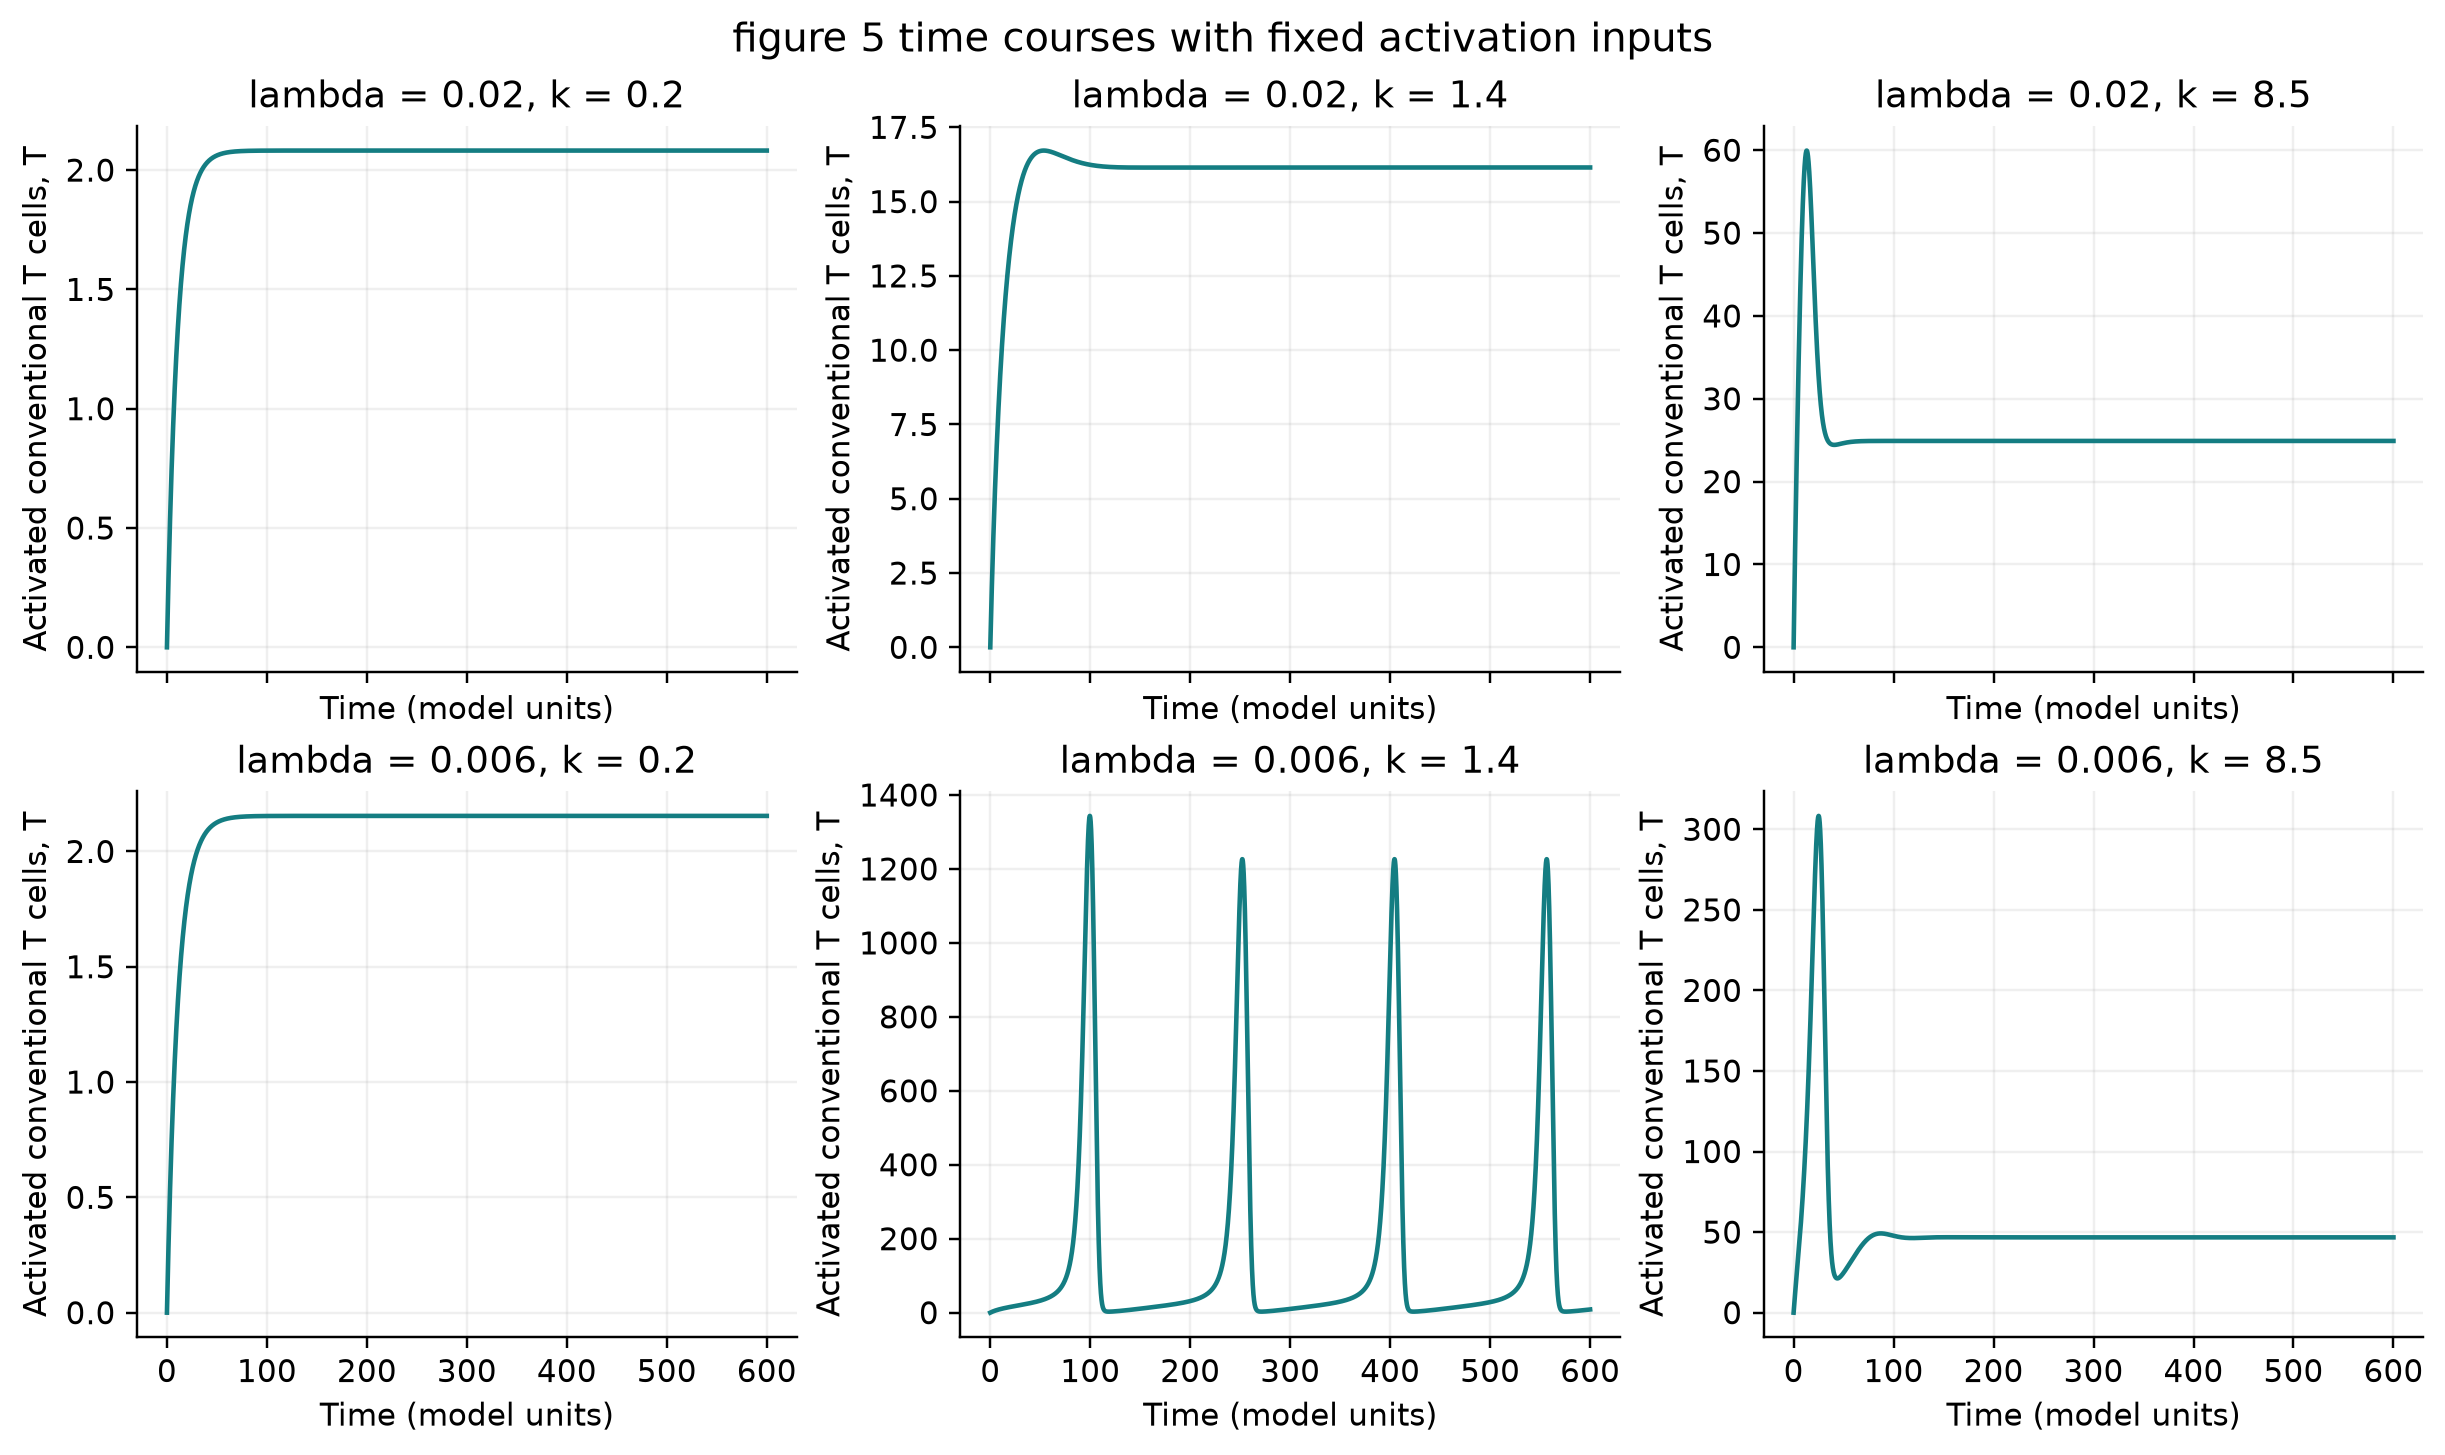

figures/02_baseline_all_states.png


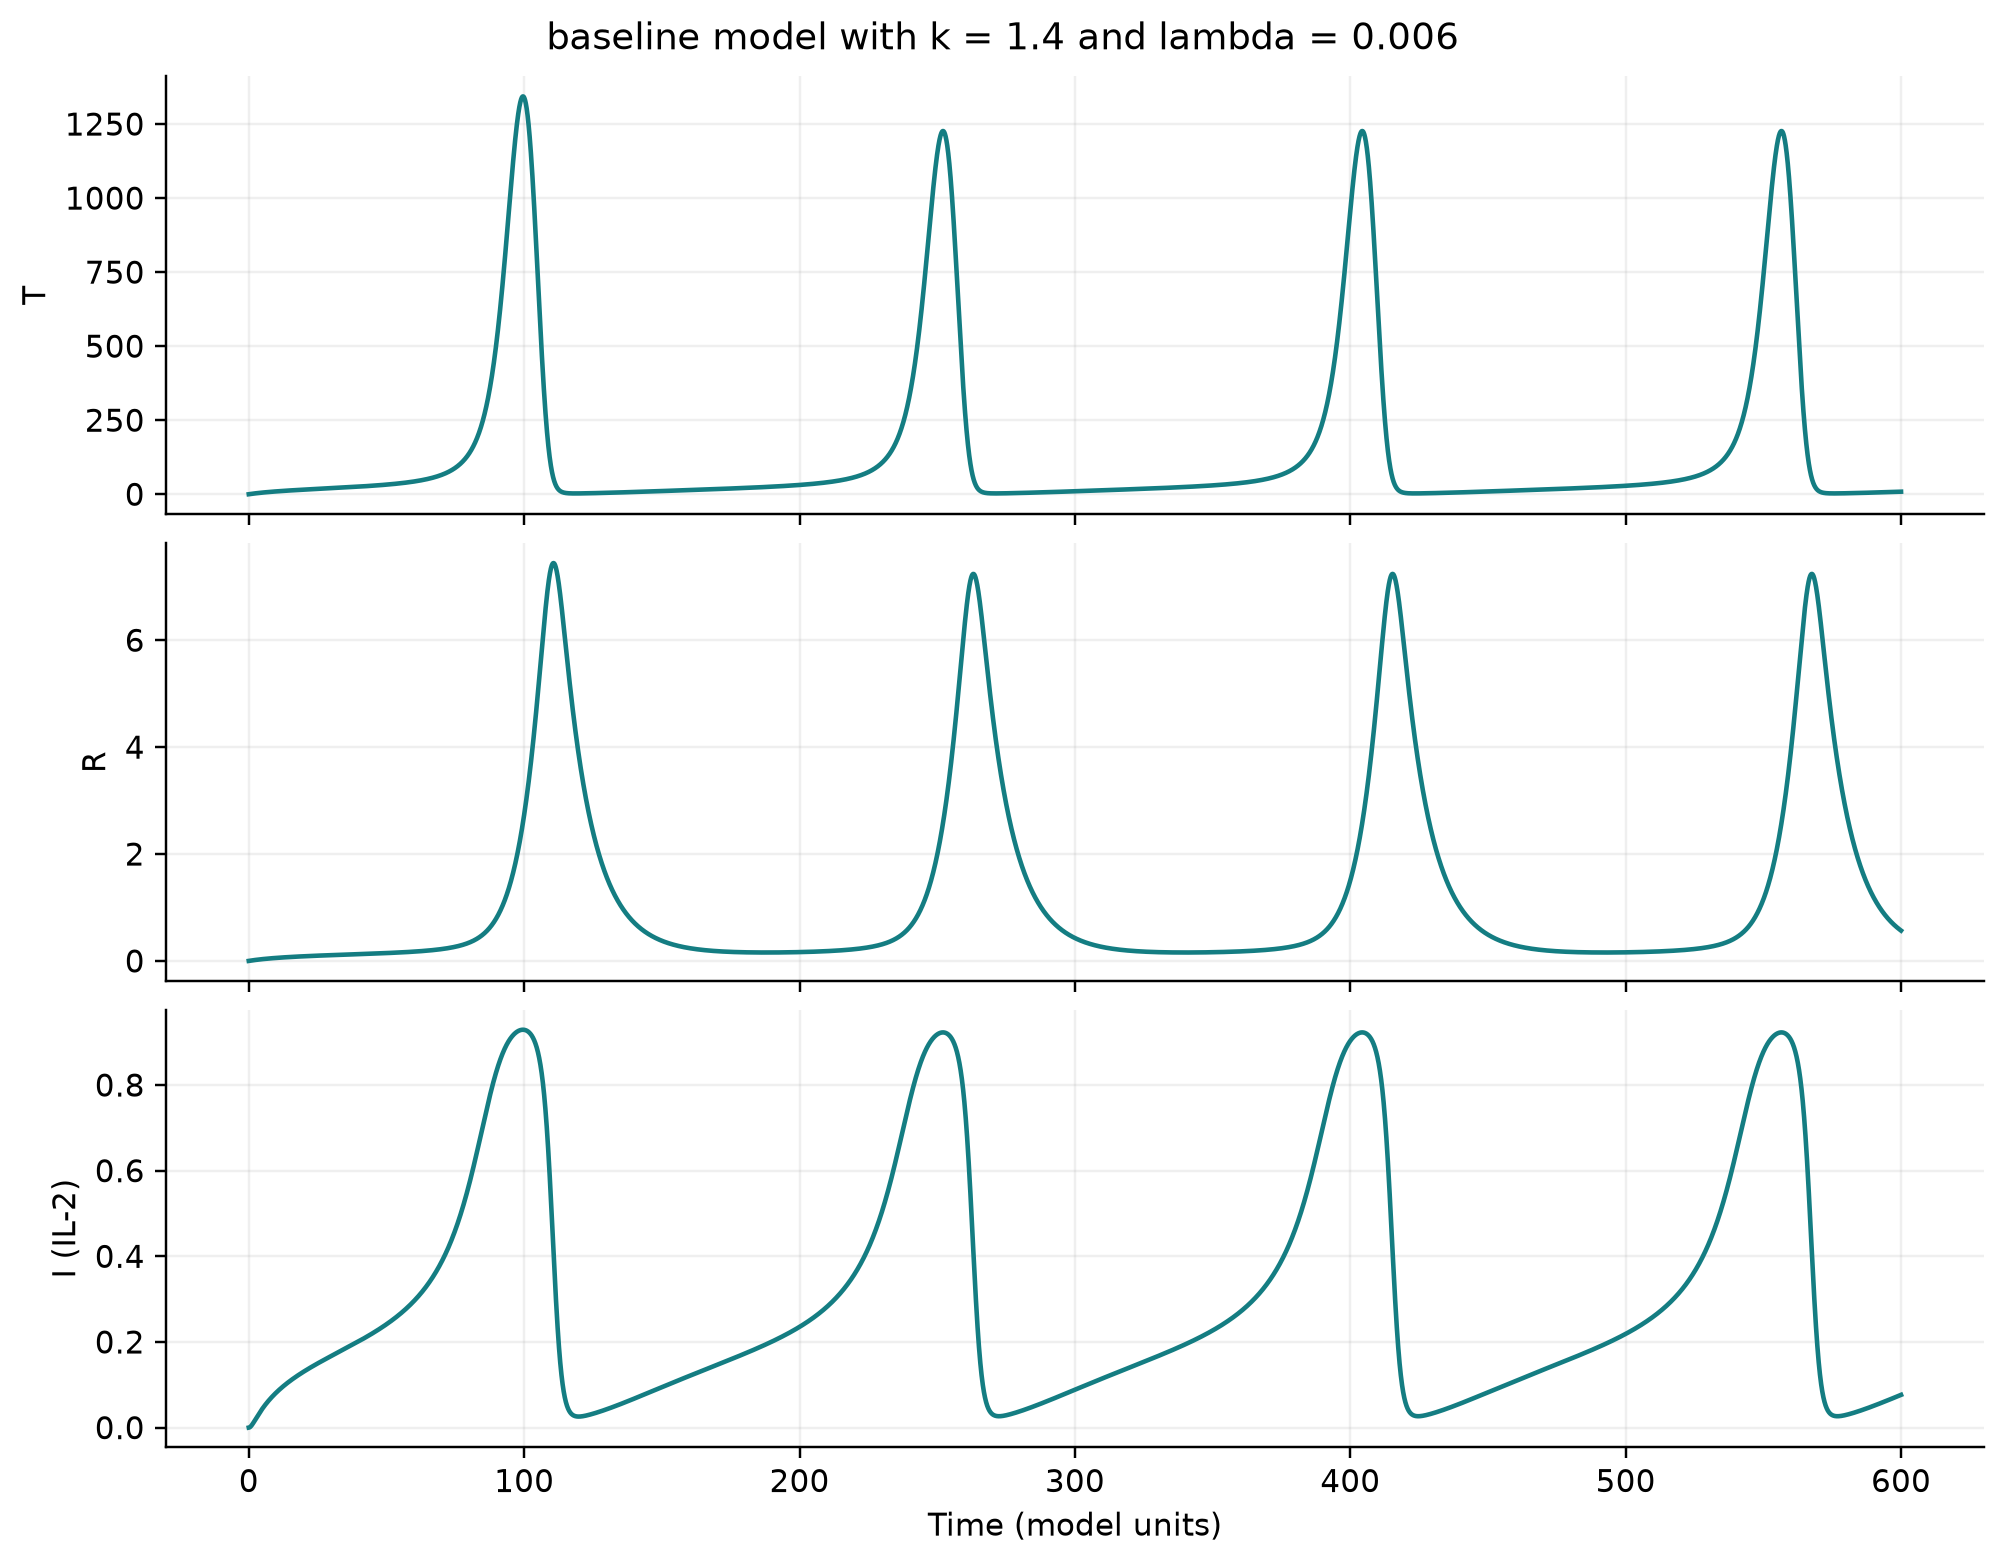

figures/03_lambda_experiment.png


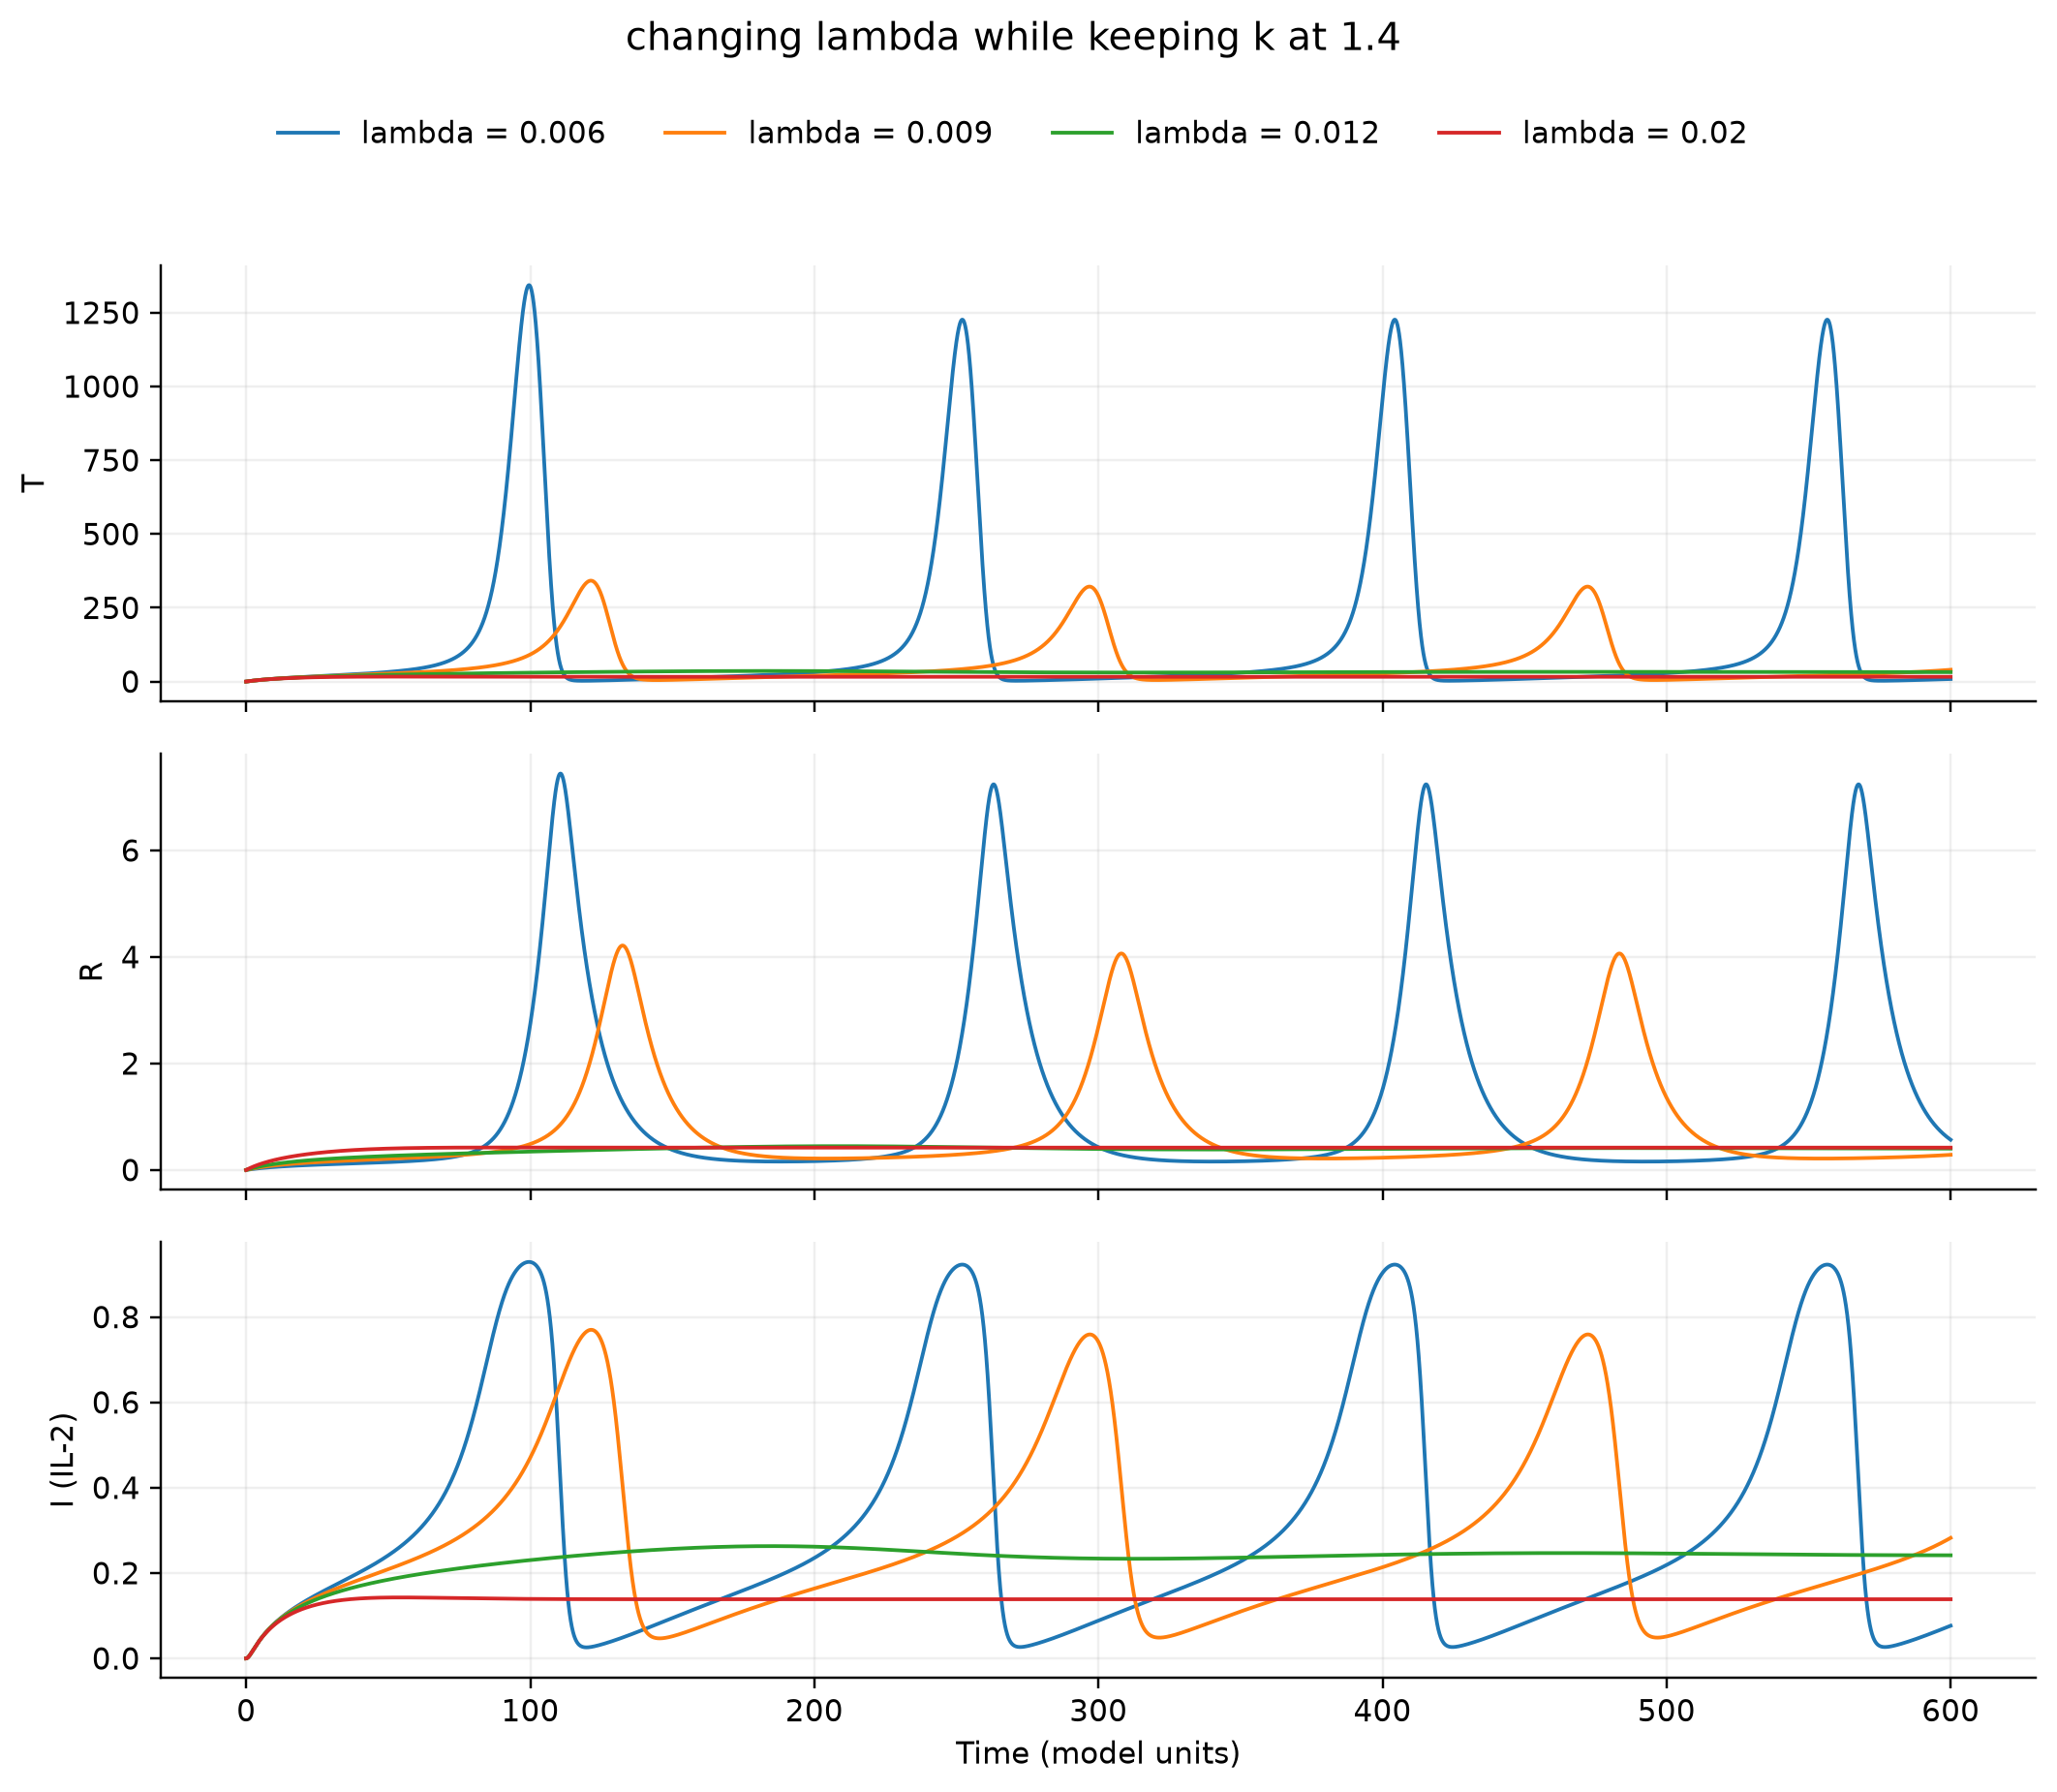

figures/04_sindy_training_windows.png


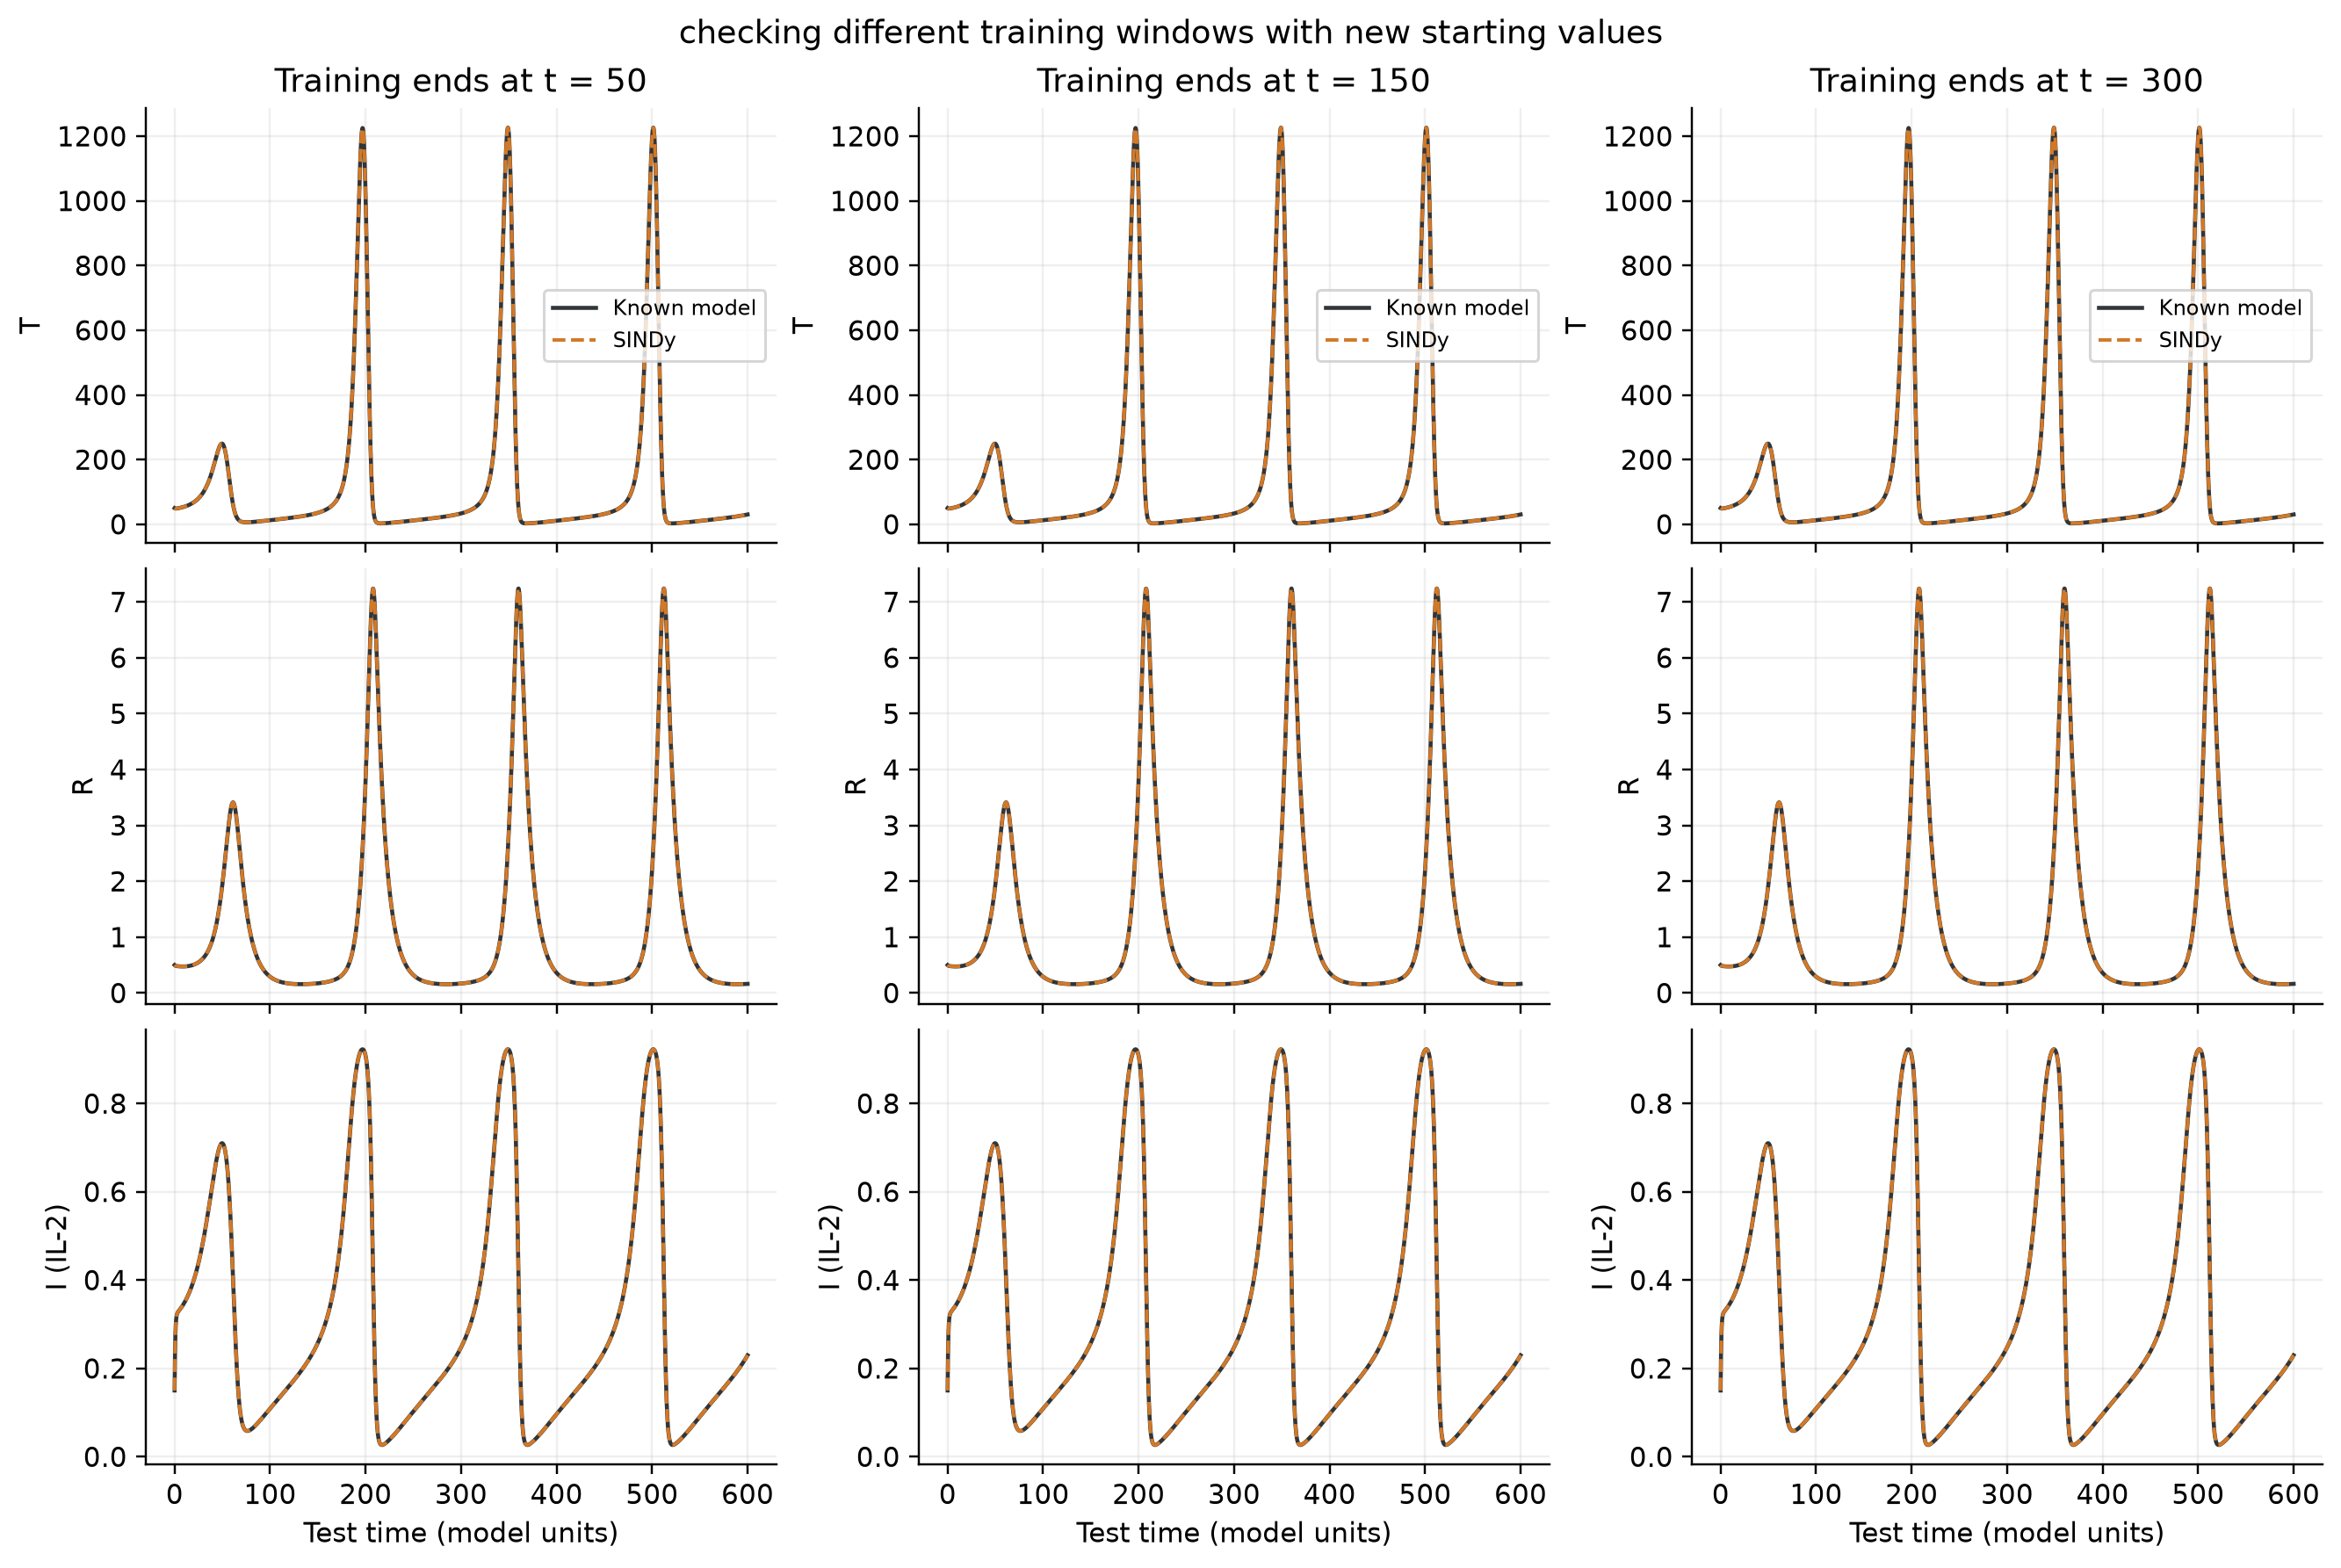

figures/05_sindy_parameter_comparison.png


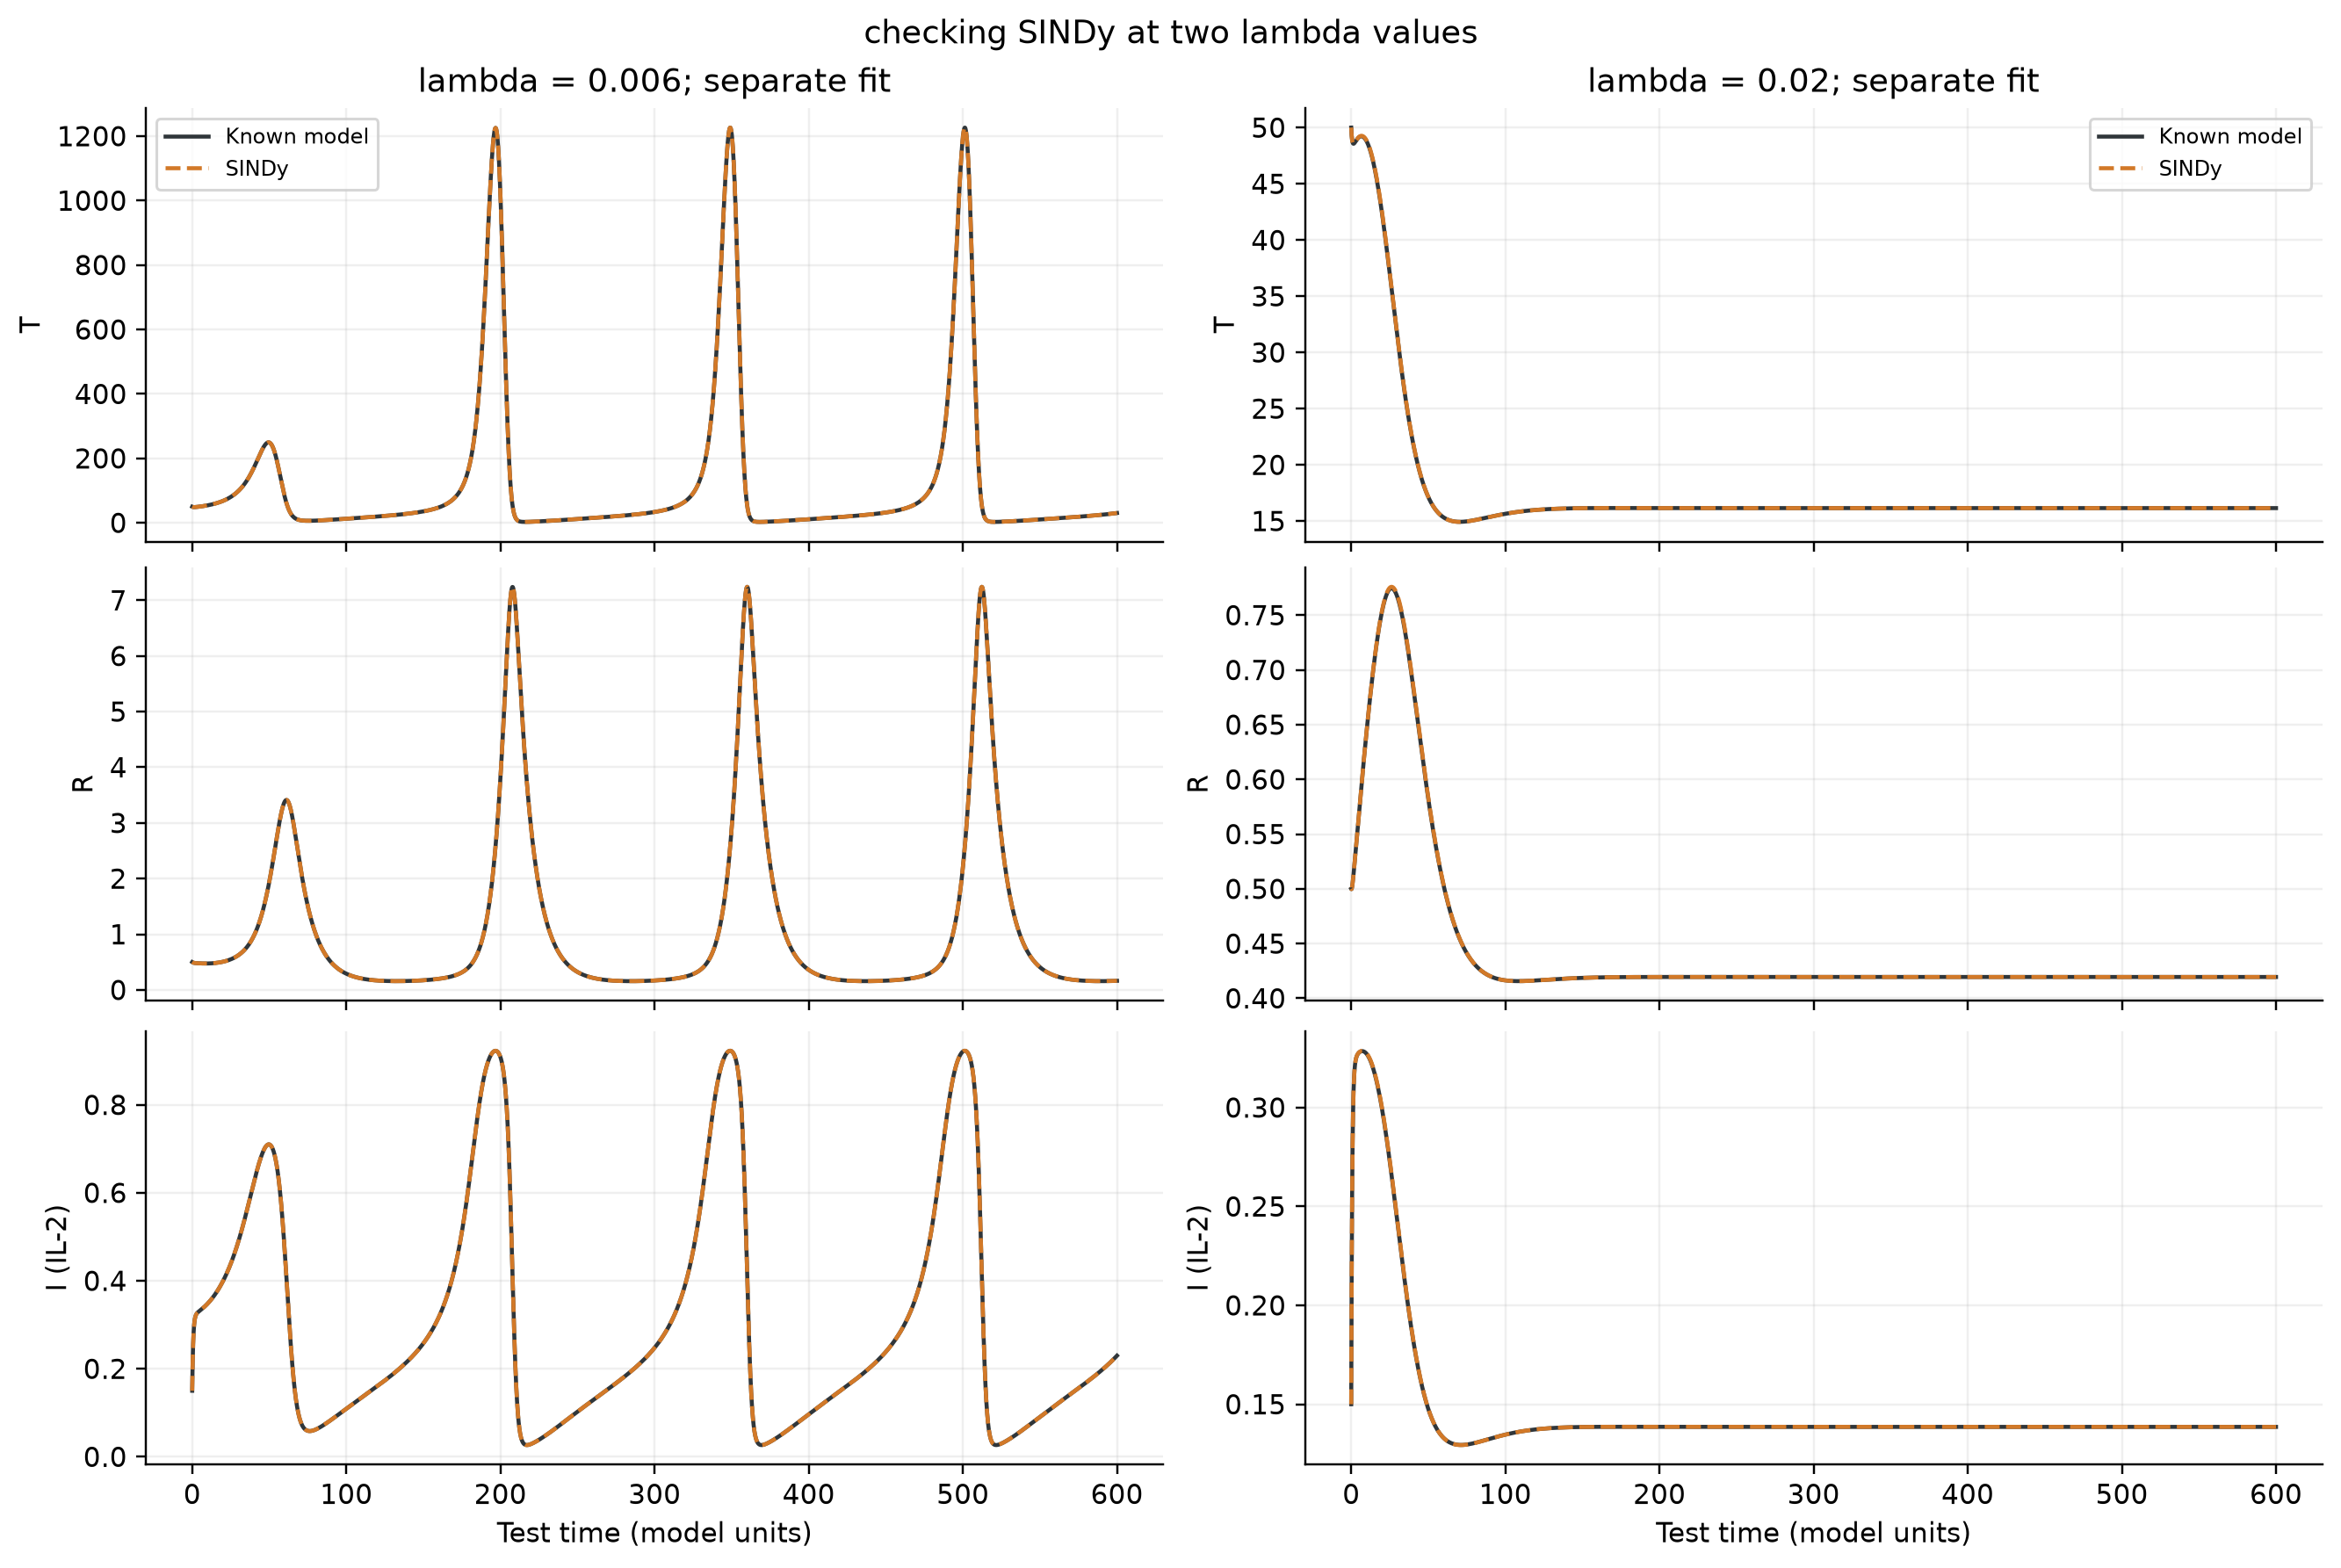

figures/06_paper_peak_comparison.png


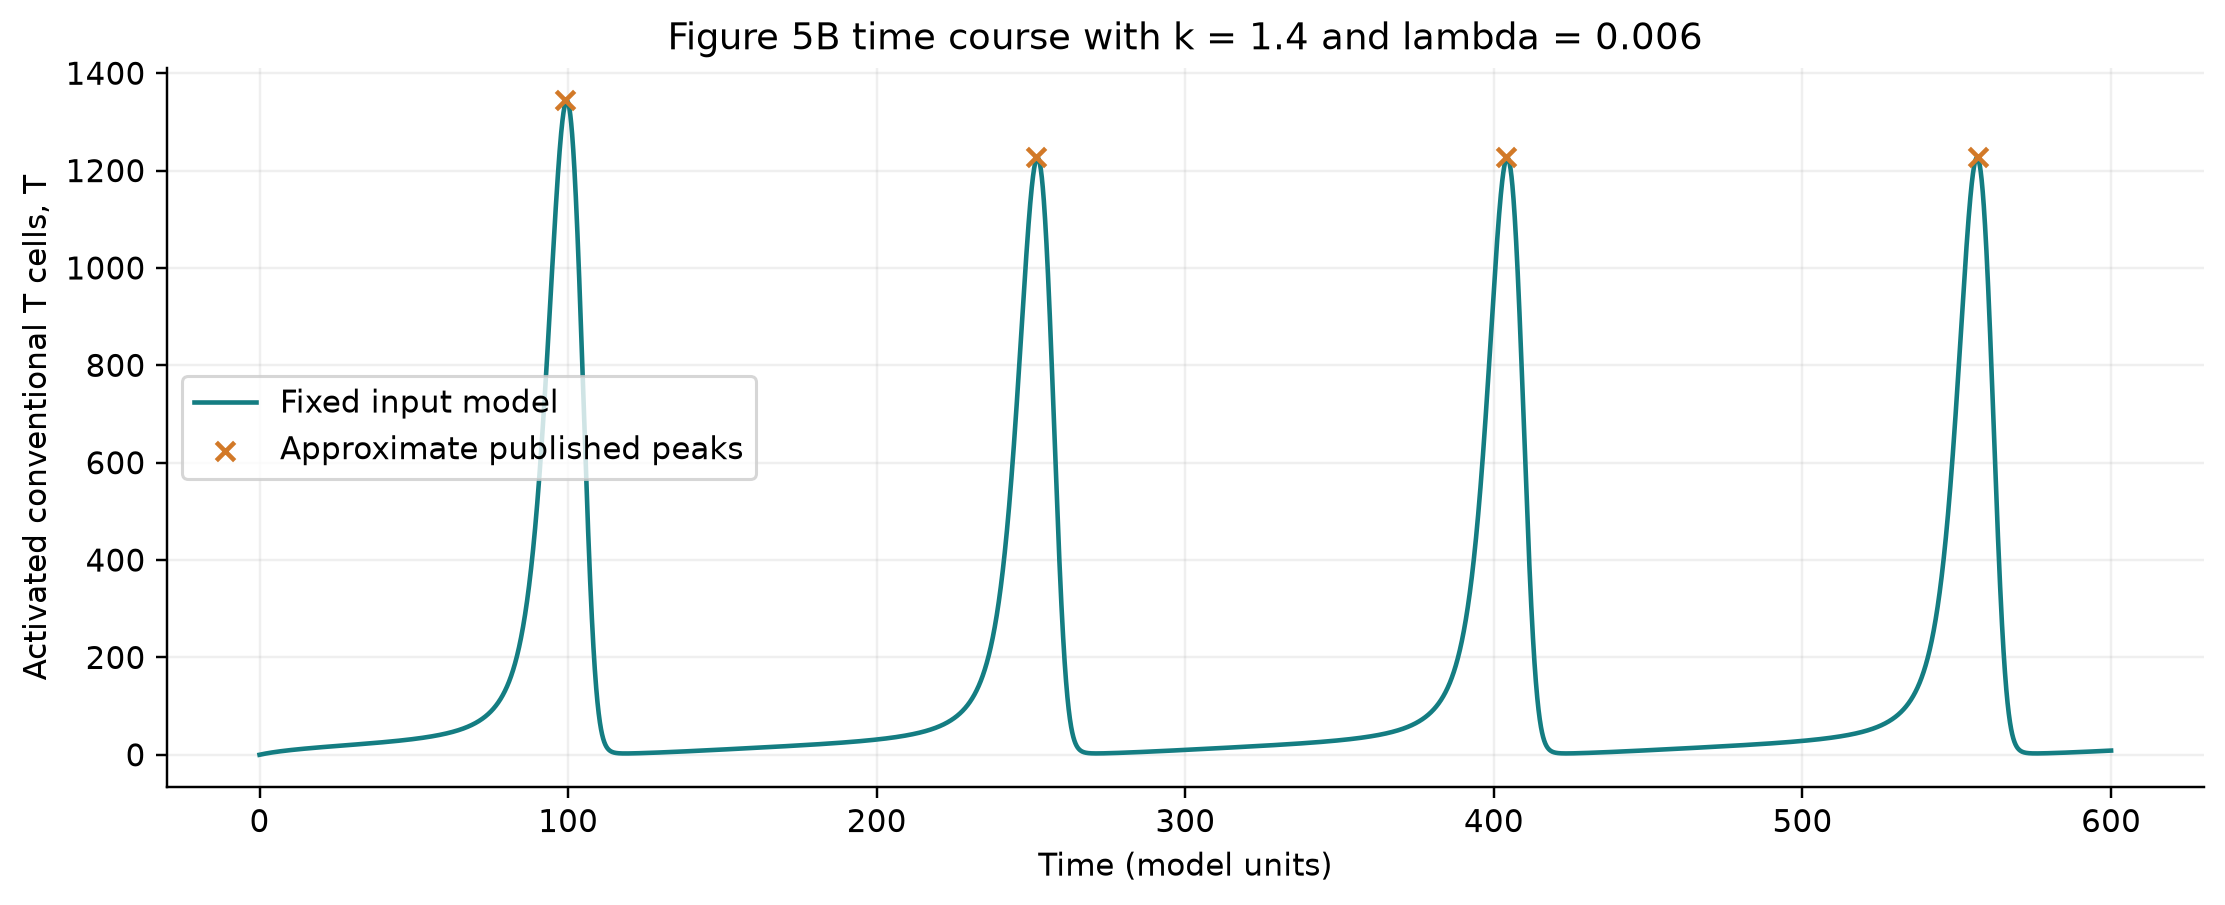

In [9]:
from IPython.display import Image, display
manifest = json.loads((output_dir / "run_manifest.json").read_text())
for filename in manifest["files"]:
    if filename.endswith(".png"):
        print(filename)
        display(Image(filename=str(output_dir / filename), width=1000))


## download the results

this zips only the files from the current run
it downloads the zip in Colab or prints its location in Jupyter


In [ ]:
from zipfile import ZipFile, ZIP_DEFLATED
archive_path = output_dir.with_name(output_dir.name + "_archive.zip")
with ZipFile(archive_path, "w", ZIP_DEFLATED) as archive:
    for filename in manifest["files"]:
        archive.write(output_dir / filename, arcname=filename)
try:
    from google.colab import files
except ImportError:
    print("Results ZIP:", archive_path.resolve())
else:
    files.download(str(archive_path))
